C:\Users\Cornell\AppData\Local\Temp\ipykernel_54504\365217313.py:136: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


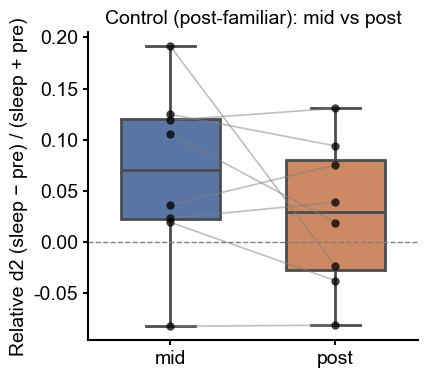

control: N paired sessions = 8
Would save to: D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\individual_fig_supp\figS2_A_control_NREM_pairedSessionMean_boxplot_pairedLines.svg


C:\Users\Cornell\AppData\Local\Temp\ipykernel_54504\365217313.py:136: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


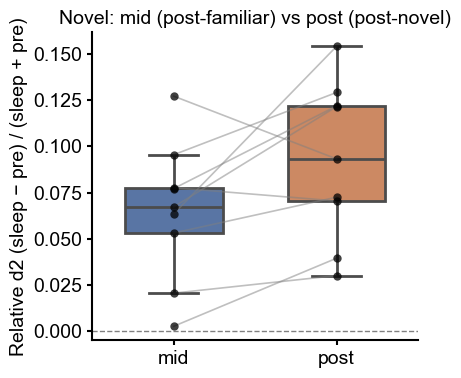

novel: N paired sessions = 9
Would save to: D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\individual_fig_supp\figS2_A_novel_NREM_pairedSessionMean_boxplot_pairedLines.svg


In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl

# -----------------------------
# Matplotlib style (keep yours)
# -----------------------------
mpl.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False
mpl.rcParams["axes.linewidth"] = 1.5
mpl.rcParams["xtick.major.width"] = 1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5

def _despine(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(False)

# -----------------------------
# Paths
# -----------------------------
base_dir = Path(r"D:\Documents\GitHub\Sleep_criticaltiy\data\novel_familiar")
folders = ["control", "novel"]

# -----------------------------
# Collect
# -----------------------------
rows = []
for sub in folders:
    dpath = base_dir / sub
    for pkl in sorted(dpath.glob("*.pkl")):
        try:
            df = pd.read_pickle(pkl)
        except Exception as e:
            print(f"Skip {pkl.name}: {e}")
            continue

        if ("epoch_group" not in df.columns) or ("d2_rel" not in df.columns):
            print(f"Skip {pkl.name}: missing columns in data")
            continue

        use = df[df["epoch_group"].isin(["midsleep", "postsleep"])].copy()
        if use.empty:
            continue

        use["file"] = pkl.stem
        use["source"] = sub
        use["phase"] = np.where(use["epoch_group"].eq("midsleep"), "mid", "post")

        rows.append(use[["file", "source", "phase", "d2_rel"]])

all_rel = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()
if all_rel.empty:
    raise ValueError("No d2_rel rows found in control/novel folders.")

# -----------------------------
# Paired session mean per phase
#   -> one value per (file, source, phase)
# -----------------------------
sess_mean = (
    all_rel
    .groupby(["file", "source", "phase"], as_index=False)["d2_rel"]
    .mean()
    .rename(columns={"d2_rel": "d2_rel_session_mean"})
)

# Pivot for pairing mid vs post within each source (folder)
wide = (
    sess_mean
    .pivot_table(index=["file", "source"], columns="phase", values="d2_rel_session_mean", aggfunc="first")
    .reset_index()
)
wide = wide.dropna(subset=["mid", "post"]).copy()  # enforce paired

# Back to long for plotting
plot_long = wide.melt(
    id_vars=["file", "source"],
    value_vars=["mid", "post"],
    var_name="phase",
    value_name="d2_rel_session_mean"
)
plot_long["phase"] = pd.Categorical(plot_long["phase"], ["mid", "post"], ordered=True)

# -----------------------------
# Plot: 2 subplots
#   left: control (mid vs post)
#   right: novel   (mid vs post)
# Boxplot of session means + paired lines
# -----------------------------
# =============================
# Make TWO SEPARATE FIGURES
# (not subplots): control + novel
# =============================

phase_order = ["mid", "post"]
titles = {
    "control": "Control (post-familiar): mid vs post",
    "novel":   "Novel: mid (post-familiar) vs post (post-novel)",
}
phase_palette = {"mid": "#4c72b0", "post": "#dd8452"}

save_dir = Path(r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\individual_fig_supp")
save_dir.mkdir(parents=True, exist_ok=True)

for src in ["control", "novel"]:

    d = plot_long[plot_long["source"].eq(src)].copy()
    if d.empty:
        print(f"{src}: no paired sessions, skip.")
        continue

    fig, ax = plt.subplots(1, 1, figsize=(4.5, 4), sharey=True)

    # Boxplot of paired session means
    sns.boxplot(
        data=d, x="phase", y="d2_rel_session_mean",
        order=phase_order,
        palette=phase_palette,
        showfliers=False, width=0.6, linewidth=2,
        ax=ax
    )

    # Paired lines (one line per session)
    for f, df_f in d.groupby("file"):
        df_f = df_f.sort_values("phase")
        # x positions match order: mid=0, post=1
        ax.plot(
            [0, 1],
            df_f["d2_rel_session_mean"].values, color="gray",linewidth=1.2,
            alpha=0.5,
            zorder=3
        )

    # Points
    sns.stripplot(
        data=d, x="phase", y="d2_rel_session_mean",
        order=phase_order,
        color="k", size=6, alpha=0.75, jitter=0,
        ax=ax, zorder=4
    )

    ax.axhline(0, ls="--", lw=1, color="gray")
    ax.set_title(titles[src])
    ax.set_xlabel("")
    ax.set_ylabel("Relative d2 (sleep − pre) / (sleep + pre)")
    _despine(ax)

    plt.tight_layout()

    # Save separate files (optional)
    out_svg = save_dir / f"figS2_A_{src}_NREM_pairedSessionMean_boxplot_pairedLines.svg"
    plt.savefig(out_svg, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"{src}: N paired sessions = {wide[wide['source'].eq(src)].shape[0]}")
    print("Would save to:", out_svg)

In [2]:
from scipy.stats import wilcoxon
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1) Aggregate to one value per file × session (median) and pivot to S1/S2
import numpy as np
import pandas as pd

# ===== mutate all_rel in place =====
# 1) daytype from source
all_rel["daytype"] = all_rel["source"].astype(str)  # 'control' or 'novel'

# 2) session (S1/S2)
if "session" not in all_rel.columns:
    if "phase" in all_rel.columns:
        all_rel["session"] = np.where(all_rel["phase"].str.lower().eq("mid"),  "S1",
                               np.where(all_rel["phase"].str.lower().eq("post"), "S2", np.nan))
    else:
        # fallback from epoch_group
        map_sess = {"midsleep":"S1", "postsleep":"S2"}
        all_rel["session"] = all_rel["epoch_group"].str.lower().map(map_sess)

# 3) exposure: only novel-day S2 is "novel", everything else is "familiar"
all_rel["exposure"] = np.where(
    (all_rel["daytype"].eq("novel")) & (all_rel["session"].eq("S2")),
    "novel", "familiar"
)

# 4) canonical 4-condition label
all_rel["label4"] = (
    all_rel["daytype"] + "-" + all_rel["session"] + " (" + all_rel["exposure"] + ")"
)
label4_order = [
    "control-S1 (familiar)",
    "control-S2 (familiar)",
    "novel-S1 (familiar)",
    "novel-S2 (novel)",
]
all_rel["label4"] = pd.Categorical(all_rel["label4"], categories=label4_order, ordered=True)

# 5) pooled 2-level label (exposure-based)
all_rel["label2"] = pd.Categorical(
    np.where(all_rel["exposure"].eq("novel"), "post-novel", "post-familiar"),
    categories=["post-familiar","post-novel"], ordered=True
)

# 6) if you want to replace your old 'condition4' with the new names:
all_rel["condition4"] = all_rel["label4"]

# (optional) keep only rows with valid session and d2_rel
all_rel = all_rel.dropna(subset=["session", "d2_rel"])
all_rel = all_rel[all_rel["session"].isin(["S1","S2"])].copy()
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import mixedlm

def lmm_paired_within_group(all_rel, daytype_label, *, random_slope=True):
    """
    Per-group LMM with file-level pairing:
      d2_rel ~ sess_bin  (S1=0, S2=1)
      random intercept (and optional random slope) by file
    Prints estimate, SE, 95% CI, p-value, and N pairs.
    """
    # 1) keep this group, aggregate to one value per file × session (median)
    d = (all_rel[all_rel["daytype"] == daytype_label]
         .groupby(["file","session"], observed=True)["d2_rel"]
         .median()
         .reset_index())

    # 2) retain only files that have BOTH S1 and S2 (true pairing)
    have_pairs = (d.pivot_table(index="file", columns="session", values="d2_rel", aggfunc="first")
                    .dropna(subset=["S1","S2"])
                    .index)
    d = d[d["file"].isin(have_pairs)].copy()
    if d.empty:
        print(f"[{daytype_label}] No paired files with both S1 and S2.")
        return None, None

    # 3) code session: S1=0, S2=1
    d["sess_bin"] = (d["session"].astype(str).str.upper() == "S2").astype(int)

    # 4) fit LMM
    re_formula = "~sess_bin" if random_slope else "~1"
    model = mixedlm("d2_rel ~ sess_bin", groups="file", re_formula=re_formula, data=d)
    try:
        fit = model.fit(method="lbfgs")
    except Exception:
        # fallback to random-intercept if slope fails to converge
        model = mixedlm("d2_rel ~ sess_bin", groups="file", re_formula="~1", data=d)
        fit = model.fit(method="lbfgs")

    est = fit.params["sess_bin"]
    se  = fit.bse["sess_bin"]
    p   = fit.pvalues["sess_bin"]
    ci  = (est - 1.96*se, est + 1.96*se)
    n_pairs = d["file"].nunique()

    print(f"[{daytype_label}] LMM (paired by file): S2−S1 = {est:.3g} "
          f"[95% CI {ci[0]:.3g}, {ci[1]:.3g}], SE={se:.3g}, p={p:.3g}, N_pairs={n_pairs}")
    return fit, d

# --- run for each group ---
fit_novel,   df_novel   = lmm_paired_within_group(all_rel, "novel",   random_slope=True)
fit_control, df_control = lmm_paired_within_group(all_rel, "control", random_slope=True)

[novel] LMM (paired by file): S2−S1 = 0.0272 [95% CI 0.00257, 0.0519], SE=0.0126, p=0.0304, N_pairs=9
[control] LMM (paired by file): S2−S1 = -0.0462 [95% CI -0.102, 0.00982], SE=0.0286, p=0.106, N_pairs=8


c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
